# Forecasting Household Electricity Tariff Bands in Sri Lanka with an Explainable Boosting Machine
### Applied Machine Learning — Individual Assignment

**Problem.** Sri Lanka's domestic electricity tariff is *block-based*: the price per unit rises steeply as a
household's monthly consumption moves past **60** and **180** units (kWh). After the 2022–2024 tariff
revisions, crossing a boundary can raise a family's bill sharply, yet most households only find out when the
bill arrives. Lanka Electricity Company (LECO) and the Ceylon Electricity Board would also like to know in
advance which customers are drifting into higher bands, so that energy-saving advice, solar promotion and
demand planning can be targeted.

**Goal.** Predict, from a household's **last 12 monthly bills** and **simple facts about the home**
(family size, house type, appliances), which tariff band its **next month's** consumption will fall in, and
**explain why**, so the household can act (e.g. reduce use of the appliances that push it into a higher band).

| Band | Monthly consumption | Meaning |
|---|---|---|
| Low | ≤ 60 units | Cheapest block |
| Medium | 61–180 units | Middle blocks |
| High | > 180 units | Most expensive blocks |

* **ML task:** 3-class classification
* **Data:** RECON-SL, a residential electricity consumption dataset for Sri Lanka (LIRNEasia with LECO,
  2026): monthly bills for 4,063 households (Oct 2022 – Oct 2024) and a household survey
* **New algorithm (not in lectures):** Explainable Boosting Machine (EBM), from InterpretML
* **Baselines:** naive "same band as recent bills", Logistic Regression, Decision Tree, KNN, Random Forest,
  XGBoost, LightGBM, CatBoost and Stacking

In [1]:
import sys, os, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import elec  # shared preprocessing module (also used by the app and API)

SEED = 42
QUICK = os.environ.get("QUICK") == "1"  # fast smoke-test mode
DATA = Path(os.environ.get("RECON_SL_DIR", ROOT / "data" / "recon_sl"))
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
BAND_SHORT = ["Low", "Medium", "High"]
BAND_COLORS = ["#2a9d8f", "#e9c46a", "#d1495b"]

import sklearn, xgboost, lightgbm, catboost, shap, interpret
print("scikit-learn", sklearn.__version__, "| interpret (EBM)", interpret.__version__, "| xgboost", xgboost.__version__,
      "| lightgbm", lightgbm.__version__, "| catboost", catboost.__version__, "| shap", shap.__version__)

scikit-learn 1.9.1 | interpret (EBM) 0.7.8 | xgboost 3.4.1 | lightgbm 4.7.0 | catboost 1.2.10 | shap 0.54.1


## 1. Data source and first look

**Source:** *Residential Electricity Consumption Dataset for Sri Lanka (RECON-SL)*, LIRNEasia in
collaboration with Lanka Electricity Company (LECO), IEEE DataPort (doi:10.21227/n1dk-q860) and
arXiv:2609.28783 (2026). The work was funded by the LACUNA Fund.

**How it was collected:** households were randomly sampled from LECO's customer base, stratified by meter
type and LECO branch, in the western coastal service area (Moratuwa, Panadura, Kalutara, Galle, Maharagama
and others). Monthly consumption comes from LECO's billing system. Household characteristics come from
face-to-face surveys in Sinhala and Tamil (wave 1, mostly December 2023 – February 2024). Households are
identified only by an anonymous ID such as `ID0001`.

This project uses:
* `monthly_consumption.csv`: 25 monthly bills per household (Oct 2022 – Oct 2024)
* Wave-1 survey tables: household information, appliances, rooms, air conditioners, water heating and cooking

In [2]:
bills = elec.load_bills(DATA)
print("Bill records:", bills.shape, "| households:", bills.household_ID.nunique(), "| months:", bills.month.nunique())
print("Raw 'consumption' values that were text with thousands separators (e.g. '1,159'):",
      int(pd.read_csv(DATA / 'consumption_data/non_smart_meter/monthly_consumption.csv').consumption.astype(str).str.contains(',').sum()))
bills.head()

Bill records: (101575, 3) | households: 4063 | months: 25
Raw 'consumption' values that were text with thousands separators (e.g. '1,159'): 57


,household_ID,month,kwh
0,ID0001,2022-10-31,116.0
1,ID0001,2022-11-30,120.0
2,ID0001,2022-12-31,129.0
3,ID0001,2023-01-31,102.0
4,ID0001,2023-02-28,115.0


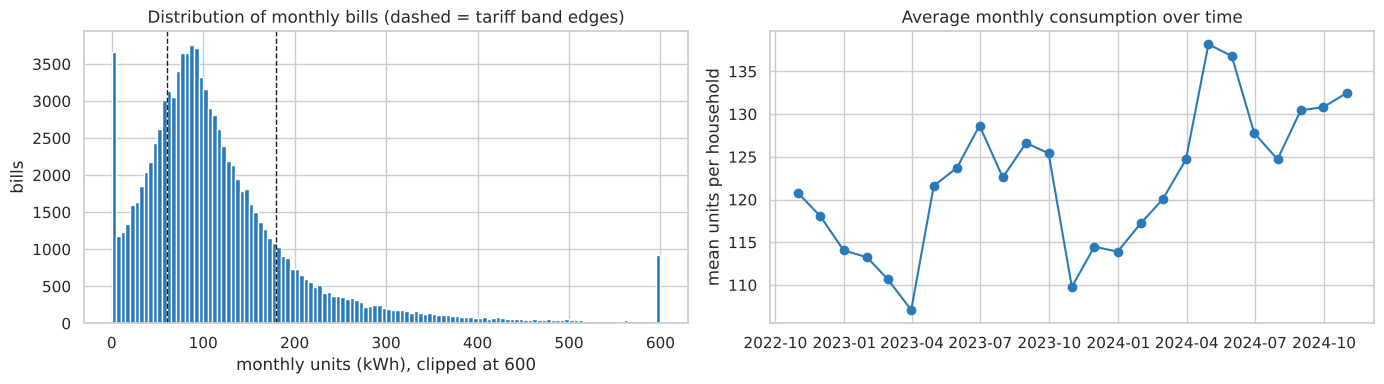

count    100985.0
mean        122.1
std         122.2
min           0.0
1%            0.0
5%           10.0
25%          60.0
50%          96.0
75%         148.0
95%         306.0
99%         577.0
max        3025.0
Name: kwh, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
k = bills.kwh.dropna()
axes[0].hist(k.clip(upper=600), bins=120, color="#2a7ab9")
for e in elec.BAND_EDGES: axes[0].axvline(e, color="k", ls="--", lw=1)
axes[0].set(xlabel="monthly units (kWh), clipped at 600", ylabel="bills", title="Distribution of monthly bills (dashed = tariff band edges)")
nat = bills.groupby("month").kwh.mean()
axes[1].plot(nat.index, nat.values, "o-", color="#2a7ab9")
axes[1].set(ylabel="mean units per household", title="Average monthly consumption over time")
fig.tight_layout(); fig.savefig(FIG / "eda_bills.png", dpi=120); plt.show()
print(k.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1))

**Observations**
* Consumption is **right-skewed**. The median household uses about 96 units a month, but the top 1% use more
  than 560, and one record shows 3,025.
* About 2.3% of bills are **zero** (vacant homes, meter faults, or solar homes exporting more than they import).
* There is a clear **seasonal pattern**: consumption peaks in the hot months (March–May) and dips mid-year.
* About 590 values were stored as **text with a thousands separator** ("1,159"). Read naively, these become
  missing values, so they were converted.

## 2. Data preprocessing

1. **Type repair:** text values such as "1,159" converted to numbers.
2. **Implausible values:** a single month above 3,000 units is beyond any domestic connection, so it is set
   to missing.
3. **Gaps:** an isolated missing month between two known months is filled by linear interpolation (a
   meter-reading gap). Longer gaps stay missing, and samples with more than 2 missing bills in the window are
   excluded.
4. **Household profile** from the wave-1 survey: family size, floor area, monthly expenditure, house type,
   home business, solar panels, electric cooking, electric water heating, number of rooms, bulbs, fans and air
   conditioners, and counts of 16 energy-relevant appliances.
5. **Encoding and scaling:** for the baseline models, numeric features are imputed (median) and scaled, and
   house type is one-hot encoded, all inside an sklearn `Pipeline`. The EBM handles missing values,
   categories and binning natively.

In [4]:
P, clean_log = elec.clean_bills(bills)
H = elec.household_profile(DATA)
display(pd.Series(clean_log, name="value").to_frame())
print("Household profile:", H.shape)
H.describe().T[["count", "mean", "50%", "max"]].round(1)

,value
raw_rows,101575
non_numeric_fixed,590
households,4063
months,25
missing_cells,591
missing_after_interpolation,486


Household profile: (4063, 29)


,count,mean,50%,max
household_members,4063.0,4.0,4.0,13.0
floor_area_sqft,4037.0,1356.2,1000.0,9000.0
monthly_expenditure_lkr,3928.0,71327.3,60000.0,275000.0
home_business,4063.0,0.0,0.0,1.0
solar_panels,4063.0,0.1,0.0,1.0
electric_cooking,4063.0,0.4,0.0,1.0
grid_water_heating,4063.0,0.2,0.0,1.0
n_fridge,4063.0,0.9,1.0,4.0
n_washing_machine,4063.0,0.6,1.0,3.0
n_iron,4063.0,0.9,1.0,5.0


### 2.1 Building the modelling table (no look-ahead)

Each row is a **household at a forecast date** (the end of a month, January–September 2024, after the
wave-1 survey). It contains **only information available on that date**:

* **Bill history features** from the last 12 bills: last bill; averages of the last 3, 6 and 12 bills;
  standard deviation; minimum and maximum; recent trend (last 3 vs the 3 before); the bill for the same month
  last year (seasonality); and the number of zero bills.
* **Calendar:** the month being predicted.
* **Household profile** from the survey.

The **target** is the tariff band of the **following month's** bill.

In [5]:
S = elec.build_samples(P, H)
print("Modelling table:", S.shape, "| households:", S.household_ID.nunique(), "| forecast dates:", S.origin.nunique())
dist = S.band.value_counts(normalize=True).sort_index().rename(index=dict(enumerate(elec.BANDS)))
display(dist.round(3).to_frame("share"))
S[["household_ID", "origin"] + elec.HISTORY_FEATURES[:5] + ["n_ac", "household_members", "target_kwh", "band"]].head()

Modelling table: (36222, 44) | households: 4038 | forecast dates: 9


,share
band,
Low (≤60 units),0.240
Medium (61–180 units),0.576
High (>180 units),0.184


,household_ID,origin,last_1,avg_last_3,avg_last_6,avg_last_12,std_last_12,n_ac,household_members,target_kwh,band
0,ID0001,2024-01-31,67.0,78.000000,88.000000,94.000000,12.179217,0.0,4,92.0,1
1,ID0002,2024-01-31,37.0,37.666667,41.666667,47.333333,10.060926,0.0,3,52.0,0
2,ID0003,2024-01-31,205.0,208.333333,201.333333,188.583333,22.216579,0.0,4,202.0,2
3,ID0004,2024-01-31,201.0,186.333333,210.500000,212.416667,36.298435,0.0,4,292.0,2
4,ID0005,2024-01-31,92.0,91.666667,93.666667,91.250000,4.493050,0.0,2,92.0,1


## 3. Exploratory data analysis

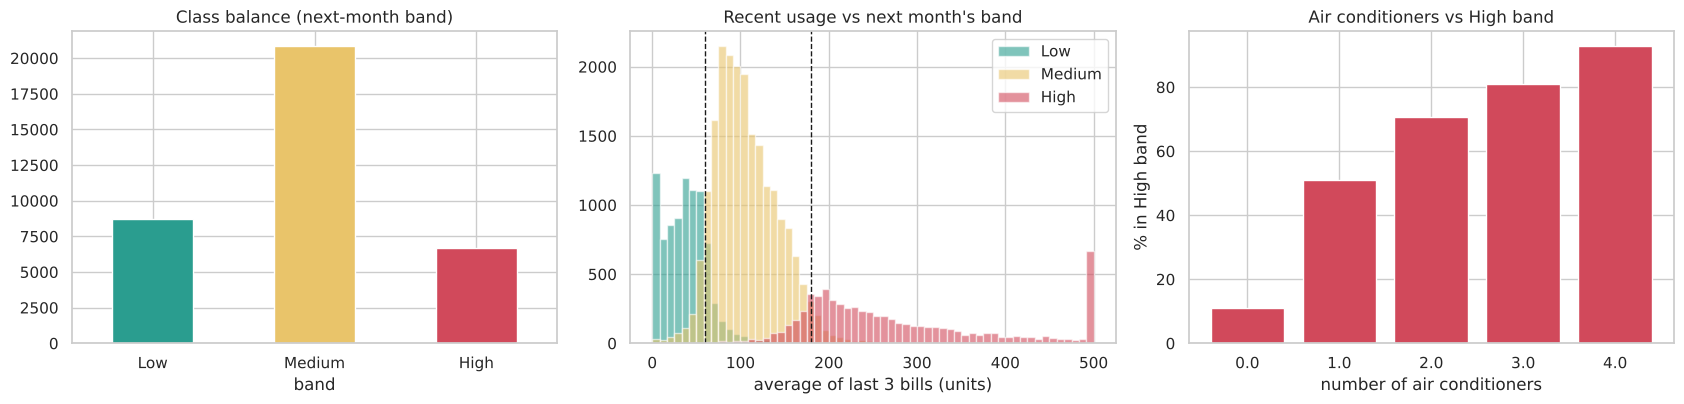

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
S.band.map(dict(enumerate(BAND_SHORT))).value_counts().reindex(BAND_SHORT).plot.bar(ax=axes[0], color=BAND_COLORS, rot=0)
axes[0].set_title("Class balance (next-month band)")
for b in range(3):
    axes[1].hist(S.loc[S.band == b, "avg_last_3"].clip(upper=500), bins=60, alpha=.6, color=BAND_COLORS[b], label=BAND_SHORT[b])
for e in elec.BAND_EDGES: axes[1].axvline(e, color="k", ls="--", lw=1)
axes[1].set(xlabel="average of last 3 bills (units)", title="Recent usage vs next month's band"); axes[1].legend()
g = S.groupby("n_ac").band.apply(lambda s: (s == 2).mean()).loc[:4]
axes[2].bar(g.index.astype(str), g.values * 100, color="#d1495b")
axes[2].set(xlabel="number of air conditioners", ylabel="% in High band", title="Air conditioners vs High band")
fig.tight_layout(); fig.savefig(FIG / "eda_overview.png", dpi=120); plt.show()

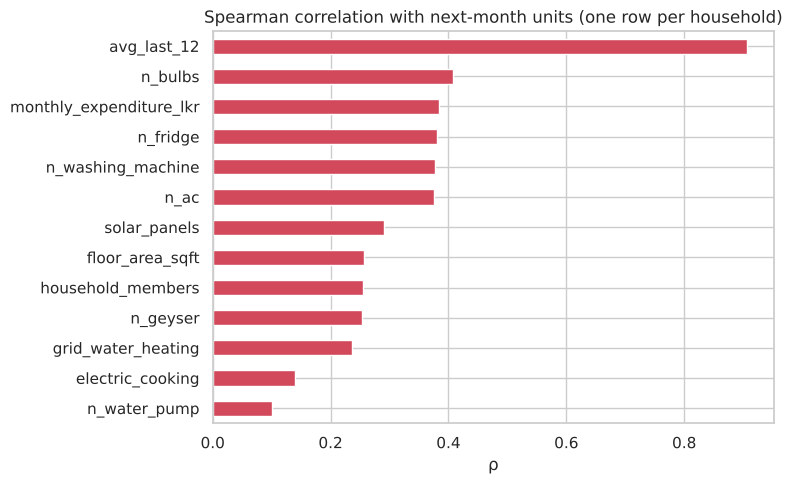

,spearman_rho
n_water_pump,0.101
electric_cooking,0.139
grid_water_heating,0.236
n_geyser,0.253
household_members,0.255
floor_area_sqft,0.257
solar_panels,0.290
n_ac,0.376
n_washing_machine,0.377
n_fridge,0.381


In [7]:
cols = ["household_members", "floor_area_sqft", "monthly_expenditure_lkr", "n_ac", "n_fridge", "n_washing_machine",
        "n_geyser", "n_water_pump", "n_bulbs", "solar_panels", "electric_cooking", "grid_water_heating", "avg_last_12"]
corr = S.drop_duplicates("household_ID")[cols + ["target_kwh"]].corr(method="spearman")["target_kwh"].drop("target_kwh").sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
corr.plot.barh(ax=ax, color=["#2a7ab9" if v < 0 else "#d1495b" for v in corr])
ax.set(title="Spearman correlation with next-month units (one row per household)", xlabel="ρ")
fig.tight_layout(); fig.savefig(FIG / "eda_correlations.png", dpi=120); plt.show()
corr.round(3).to_frame("spearman_rho")

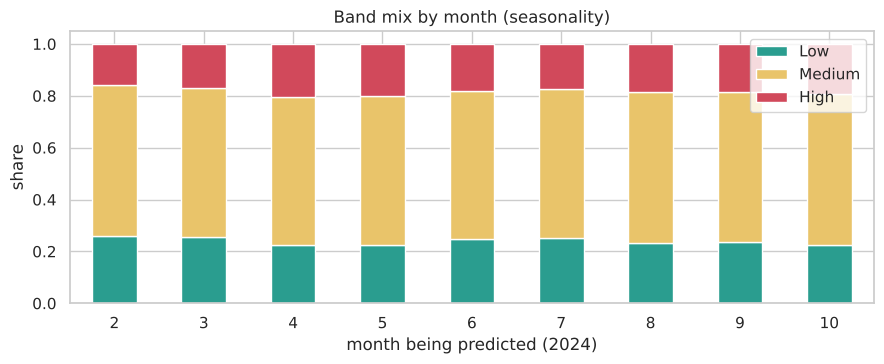

In [8]:
by_month = S.groupby("target_start_month").band.value_counts(normalize=True).unstack().reindex(columns=[0, 1, 2])
fig, ax = plt.subplots(figsize=(9, 3.8))
by_month.plot.bar(stacked=True, ax=ax, color=BAND_COLORS, rot=0); ax.legend(BAND_SHORT, loc="upper right")
ax.set(xlabel="month being predicted (2024)", ylabel="share", title="Band mix by month (seasonality)")
fig.tight_layout(); fig.savefig(FIG / "eda_season.png", dpi=120); plt.show()

**EDA findings**
* **Classes:** Medium is the majority (about 58%), with Low (about 23%) and High (about 19%). Because the
  classes are imbalanced, **balanced accuracy and macro-F1** are reported alongside accuracy.
* **Recent usage is by far the strongest signal.** Households rarely jump bands, so the most informative
  cases are those **near the 60 and 180 boundaries**.
* **Air conditioners** sharply increase the chance of being in the High band. Floor area, monthly
  expenditure, number of bulbs, refrigerators, washing machines and electric water heaters are also positively
  correlated with consumption, while **solar panels** reduce billed units.
* **Seasonality:** the share of High-band months rises in the hot season (April–May).

## 4. Leakage check and the naive baseline

**Leakage control.** Every feature is computed from bills up to the forecast date and from the survey. The
target bill is never used as an input, and the train, validation and test sets contain **different
households** (Section 5). The survey was carried out mostly in December 2023 – February 2024, close to the
first forecast date. Appliance stock changes slowly, so it is treated as known.

**Naive baseline.** A useful model must beat the simple rule: *"next month's band = the band of the
average of the last 3 bills"*. This is how a household or utility would guess without machine learning.

## 5. Train / validation / test split (by household)

| Set | Share of households | Used for |
|---|---|---|
| Training | 60% | Fitting and hyperparameter tuning (3-fold **GroupKFold**: a household never appears in two folds) |
| Validation | 20% | Comparing tuned models, choosing the final model |
| Test | 20% | Reported once, at the end |

Splitting **by household** (not by row) is essential. Each household contributes up to 9 rows (one per
forecast date), so a row-level split would let the model memorise households and inflate the scores. Three
households are also held back completely as "new customers" for the inference demonstration.

In [9]:
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
rng = np.random.default_rng(SEED)
all_hh = S.household_ID.unique()
demo_hh = rng.choice(all_hh, 3, replace=False)
data = S[~S.household_ID.isin(demo_hh)].reset_index(drop=True)

g1 = GroupShuffleSplit(1, test_size=0.20, random_state=SEED)
trval_idx, test_idx = next(g1.split(data, groups=data.household_ID))
trval = data.iloc[trval_idx]
g2 = GroupShuffleSplit(1, test_size=0.25, random_state=SEED)
tr_idx, val_idx = next(g2.split(trval, groups=trval.household_ID))
train, val, test = trval.iloc[tr_idx], trval.iloc[val_idx], data.iloc[test_idx]

def XY(d): return d[elec.FEATURES], d["band"].astype(int)
X_train, y_train = XY(train); X_val, y_val = XY(val); X_test, y_test = XY(test)
assert not set(train.household_ID) & set(test.household_ID) and not set(val.household_ID) & set(test.household_ID)
split = pd.DataFrame({"households": [train.household_ID.nunique(), val.household_ID.nunique(), test.household_ID.nunique()],
                      "rows": [len(train), len(val), len(test)],
                      "Low": [(d.band == 0).mean() for d in (train, val, test)],
                      "Medium": [(d.band == 1).mean() for d in (train, val, test)],
                      "High": [(d.band == 2).mean() for d in (train, val, test)]}, index=["train", "validation", "test"])
display(split.round(3))
cv3 = GroupKFold(n_splits=3)
groups_train = train.household_ID.to_numpy()

,households,rows,Low,Medium,High
train,2421,21710,0.245,0.564,0.191
validation,807,7236,0.237,0.594,0.169
test,807,7249,0.231,0.591,0.177


In [10]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, roc_auc_score, confusion_matrix,
                             classification_report, log_loss)
def metrics(name, y, proba):
    yhat = proba.argmax(1)
    return {"model": name, "accuracy": accuracy_score(y, yhat), "balanced_acc": balanced_accuracy_score(y, yhat),
            "macro_f1": f1_score(y, yhat, average="macro"), "weighted_f1": f1_score(y, yhat, average="weighted"),
            "macro_auc": roc_auc_score(y, proba, multi_class="ovr", average="macro"), "log_loss": log_loss(y, proba)}

def naive_proba(X):
    b = elec.band_of(X["avg_last_3"]); p = np.full((len(X), 3), 0.01); p[np.arange(len(X)), b] = 0.98
    return p  # hard rule expressed as (near-certain) probabilities that sum to 1

naive_val = metrics("Naive: band of last-3-bill average", y_val, naive_proba(X_val))
pd.DataFrame([naive_val]).round(4)

,model,accuracy,balanced_acc,macro_f1,weighted_f1,macro_auc,log_loss
0,Naive: band of last-3-bill average,0.8915,0.8761,0.88,0.8915,0.904,0.5176


## 6. The new algorithm: Explainable Boosting Machine (EBM)

### 6.1 How it works
An EBM (Lou et al., 2013; Nori et al., 2019) is a **Generalised Additive Model with pairwise interactions
(GA²M)** trained by gradient boosting. For each class *k*:

$$\log\frac{P(y=k)}{P(y=\text{ref})} \;=\; \beta_{0k} + \sum_j f_{jk}(x_j) + \sum_{(i,j)} f_{ijk}(x_i, x_j)$$

* $f_j$ is a **shape function**: a learned curve showing how one feature (e.g. number of ACs) changes the score.
* $f_{ij}$ is a small 2-D surface for an **automatically detected pair** (e.g. recent usage × season).
* **Training (cyclic boosting):** with a very small learning rate, EBM visits the features in turn and fits a
  tiny tree on *one feature only* to the current residuals, adding it to that feature's curve. Repeating this
  thousands of times builds each curve separately, so the effects stay **additive and readable**.
* **Bagging:** the whole process is repeated on bootstrap samples (`outer_bags`) and averaged, which reduces
  variance and gives confidence bands.

### 6.2 Why it was selected
1. **Glass-box explanations, which the app depends on.** Because the prediction is a sum of per-feature
   terms, the app can tell a household *exactly* how much each part of its bill history, the season and its home
   contributes to the forecast. A black-box model can only approximate this afterwards with SHAP or LIME.
2. **It fits the problem's structure.** Thresholded, non-linear effects (e.g. usage near 60 or 180 units)
   and interactions with season are captured by shape functions and pairwise terms.
3. **Accuracy comparable to boosted trees** on tabular data, tested here against XGBoost, LightGBM and CatBoost.
4. **Not covered in the lectures**, and not deep learning.

### 6.3 How it differs from the standard models

| | Logistic regression | Decision tree | k-NN | RF / XGBoost / LightGBM | **EBM** |
|---|---|---|---|---|---|
| Feature effects | Linear | Steps, features mixed | No explicit model | Many deep trees mixing all features | **One flexible curve per feature** |
| Interactions | Only if added by hand | Implicit | Implicit | Implicit, hidden | **Explicit, selected pairs** |
| Explanation | Coefficients | Only if shallow | None | Needs SHAP/LIME | **Exact, built in** |
| Training | Convex optimisation | Greedy splitting | Memorises data | Bagging/boosting over all features | **Cyclic one-feature boosting + bagging** |

### 6.4 Hyperparameter tuning
None of the models use default settings. Each is tuned with `RandomizedSearchCV` using **GroupKFold (3
folds) on the training households**, scored by accuracy. The EBM search covers `interactions` (0–15),
`learning_rate` (0.005–0.05), `max_bins` (64–512), `min_samples_leaf` (2–50), `max_leaves` (2–4) and
`outer_bags` (8–14).

In [11]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from interpret.glassbox import ExplainableBoostingClassifier
from scipy.stats import randint, uniform, loguniform

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), elec.NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore"), elec.CATEGORICAL)])

EBM_NAME = "EBM (new algorithm)"
def make_pipeline(name, est):
    return Pipeline([("pre", "passthrough" if name == EBM_NAME else make_preprocessor()), ("model", est)])

search_spaces = {
    EBM_NAME: (ExplainableBoostingClassifier(random_state=SEED, n_jobs=-1), 6, {
        "model__interactions": [0, 5, 10, 15], "model__learning_rate": loguniform(0.005, 0.05),
        "model__max_bins": [64, 128, 256, 512], "model__min_samples_leaf": randint(2, 50),
        "model__max_leaves": [2, 3, 4], "model__outer_bags": [8, 14]}),
    "Logistic Regression": (LogisticRegression(max_iter=4000), 8, {
        "model__C": loguniform(1e-3, 1e2), "model__class_weight": [None, "balanced"]}),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), 20, {
        "model__max_depth": randint(3, 16), "model__min_samples_leaf": randint(5, 200), "model__criterion": ["gini", "entropy"]}),
    "KNN": (KNeighborsClassifier(), 8, {"model__n_neighbors": randint(5, 151), "model__weights": ["uniform", "distance"]}),
    "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1), 8, {
        "model__n_estimators": randint(200, 500), "model__max_depth": randint(6, 24),
        "model__min_samples_leaf": randint(2, 50), "model__max_features": ["sqrt", 0.3, 0.5]}),
    "XGBoost": (XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="mlogloss"), 12, {
        "model__n_estimators": randint(200, 800), "model__max_depth": randint(2, 8),
        "model__learning_rate": loguniform(0.01, 0.2), "model__subsample": uniform(0.6, 0.4),
        "model__colsample_bytree": uniform(0.5, 0.5), "model__min_child_weight": randint(1, 30),
        "model__reg_lambda": loguniform(0.1, 20)}),
    "LightGBM": (LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1), 12, {
        "model__n_estimators": randint(200, 900), "model__num_leaves": randint(8, 64),
        "model__learning_rate": loguniform(0.01, 0.2), "model__min_child_samples": randint(10, 150),
        "model__subsample": uniform(0.6, 0.4), "model__subsample_freq": [1],
        "model__colsample_bytree": uniform(0.5, 0.5), "model__reg_lambda": loguniform(0.1, 20)}),
    "CatBoost": (CatBoostClassifier(random_state=SEED, verbose=0, thread_count=-1, allow_writing_files=False), 6, {
        "model__iterations": randint(300, 900), "model__depth": randint(4, 8),
        "model__learning_rate": loguniform(0.02, 0.2), "model__l2_leaf_reg": loguniform(1, 20)}),
}

tuned, rows = {}, []
for name, (est, n_iter, space) in search_spaces.items():
    t0 = time.time()
    rs = RandomizedSearchCV(make_pipeline(name, est), space, n_iter=1 if QUICK else n_iter, cv=cv3, scoring="accuracy",
                            random_state=SEED, n_jobs=1, return_train_score=True)
    rs.fit(X_train, y_train, groups=groups_train)
    tuned[name] = rs.best_estimator_; i = rs.best_index_
    rows.append({"model": name, "cv_accuracy": rs.best_score_, "cv_sd": rs.cv_results_["std_test_score"][i],
                 "train_accuracy": rs.cv_results_["mean_train_score"][i], "fit_time_s": round(time.time() - t0),
                 "best_params": {k.replace("model__", ""): (round(v, 4) if isinstance(v, float) else v) for k, v in rs.best_params_.items()}})
    print(f"{name:22s} CV accuracy {rs.best_score_:.4f} ± {rs.cv_results_['std_test_score'][i]:.4f}  ({rows[-1]['fit_time_s']}s)")

EBM (new algorithm)    CV accuracy 0.8926 ± 0.0022  (398s)


Logistic Regression    CV accuracy 0.8842 ± 0.0023  (6s)


Decision Tree          CV accuracy 0.8917 ± 0.0019  (13s)


KNN                    CV accuracy 0.7417 ± 0.0174  (35s)


Random Forest          CV accuracy 0.8938 ± 0.0019  (163s)


XGBoost                CV accuracy 0.8937 ± 0.0025  (92s)


LightGBM               CV accuracy 0.8928 ± 0.0009  (144s)


CatBoost               CV accuracy 0.8938 ± 0.0018  (87s)


In [12]:
# Effect of tuning: default vs tuned (3-fold GroupKFold accuracy on the training households)
default_rows = []
for name in [EBM_NAME, "Decision Tree", "Random Forest", "XGBoost", "LightGBM"]:
    est = sklearn.base.clone(search_spaces[name][0])
    s = cross_val_score(make_pipeline(name, est), X_train, y_train, groups=groups_train, cv=cv3, scoring="accuracy").mean()
    default_rows.append({"model": name, "default_cv_accuracy": s})
tuning_gain = pd.DataFrame(rows)[["model", "cv_accuracy"]].merge(pd.DataFrame(default_rows), on="model")
tuning_gain["gain"] = tuning_gain.cv_accuracy - tuning_gain.default_cv_accuracy
tuning_gain.round(4)

,model,cv_accuracy,default_cv_accuracy,gain
0,EBM (new algorithm),0.8926,0.8912,0.0014
1,Decision Tree,0.8917,0.8192,0.0725
2,Random Forest,0.8938,0.8893,0.0045
3,XGBoost,0.8937,0.8824,0.0114
4,LightGBM,0.8928,0.8879,0.0049


In [13]:
# Stacking baseline: tuned RF + XGB + LGBM + CatBoost -> logistic meta-learner (cross-validated stacking)
base = [(n.replace(" ", "_").lower(), tuned[n].named_steps["model"]) for n in ["Random Forest", "XGBoost", "LightGBM", "CatBoost"]]
stack = Pipeline([("pre", make_preprocessor()),
                  ("model", StackingClassifier(estimators=base, final_estimator=LogisticRegression(max_iter=3000),
                                               cv=3, stack_method="predict_proba", n_jobs=1))])
t0 = time.time(); stack.fit(X_train, y_train); tuned["Stacking"] = stack
rows.append({"model": "Stacking", "cv_accuracy": np.nan, "cv_sd": np.nan, "train_accuracy": np.nan,
             "fit_time_s": round(time.time() - t0), "best_params": {"base": "RF+XGB+LGBM+CatBoost", "meta": "LogReg"}})
cv_table = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 200)
cv_table.round(4)

,model,cv_accuracy,cv_sd,train_accuracy,fit_time_s,best_params
0,EBM (new algorithm),0.8926,0.0022,0.9017,398,"{'interactions': 15, 'learning_rate': 0.0053, 'max_bins': 256, 'max_leaves': 4, 'min_samples_leaf': 43, 'outer_bags': 14}"
1,Logistic Regression,0.8842,0.0023,0.8883,6,"{'C': 0.9847, 'class_weight': None}"
2,Decision Tree,0.8917,0.0019,0.8951,13,"{'criterion': 'gini', 'max_depth': 6, 'min_samples_leaf': 97}"
3,KNN,0.7417,0.0174,0.7668,35,"{'n_neighbors': 79, 'weights': 'uniform'}"
4,Random Forest,0.8938,0.0019,0.9056,163,"{'max_depth': 13, 'max_features': 0.5, 'min_samples_leaf': 23, 'n_estimators': 457}"
5,XGBoost,0.8937,0.0025,0.9074,92,"{'colsample_bytree': 0.9162, 'learning_rate': 0.0189, 'max_depth': 5, 'min_child_weight': 21, 'n_estimators': 360, 'reg_lambda': 0.5013, 'subsample': 0.8099}"
6,LightGBM,0.8928,0.0009,0.9136,144,"{'colsample_bytree': 0.8777, 'learning_rate': 0.0357, 'min_child_samples': 63, 'n_estimators': 305, 'num_leaves': 11, 'reg_lambda': 0.2663, 'subsample': 0.9878, 'subsample_freq': 1}"
7,CatBoost,0.8938,0.0018,0.8969,87,"{'depth': 4, 'iterations': 320, 'l2_leaf_reg': 1.5958, 'learning_rate': 0.0286}"
8,Stacking,NaN,NaN,NaN,75,"{'base': 'RF+XGB+LGBM+CatBoost', 'meta': 'LogReg'}"


## 7. Evaluation

**Metrics.** Accuracy (the share of correct band predictions), **balanced accuracy** and **macro-F1** (which
weight the three bands equally, because Medium dominates), **macro one-vs-rest ROC-AUC** (ranking quality)
and **log-loss** (probability quality). Every model is compared with the naive baseline.

In [14]:
p_val = {n: m.predict_proba(X_val) for n, m in tuned.items()}
val_table = pd.DataFrame([naive_val] + [metrics(n, y_val, p) for n, p in p_val.items()]).sort_values("accuracy", ascending=False)
val_table.round(4)

,model,accuracy,balanced_acc,macro_f1,weighted_f1,macro_auc,log_loss
6,XGBoost,0.9038,0.8919,0.8937,0.9038,0.9746,0.2561
5,Random Forest,0.9038,0.8896,0.8933,0.9037,0.9737,0.2609
7,LightGBM,0.9038,0.8935,0.8941,0.9038,0.9747,0.2563
8,CatBoost,0.9033,0.8897,0.8930,0.9031,0.9741,0.2605
9,Stacking,0.9026,0.8843,0.8914,0.9022,0.9725,0.2761
1,EBM (new algorithm),0.9020,0.8884,0.8918,0.9019,0.9750,0.2554
3,Decision Tree,0.9015,0.8887,0.8912,0.9014,0.9660,0.2871
2,Logistic Regression,0.9012,0.8774,0.8895,0.9007,0.9703,0.3175
0,Naive: band of last-3-bill average,0.8915,0.8761,0.8800,0.8915,0.9040,0.5176
4,KNN,0.7576,0.6673,0.7094,0.7474,0.8963,0.6287


In [15]:
# Paired bootstrap over HOUSEHOLDS on the validation set: EBM vs every other model (accuracy difference)
rng = np.random.default_rng(SEED)
vh = val.household_ID.to_numpy(); uniq = np.unique(vh); idx_by_h = {h: np.where(vh == h)[0] for h in uniq}
yv = y_val.to_numpy(); B = 400
pred = {n: p.argmax(1) for n, p in p_val.items()}; pred["Naive"] = naive_proba(X_val).argmax(1)
boots = [np.concatenate([idx_by_h[h] for h in rng.choice(uniq, len(uniq))]) for _ in range(B)]
comp = []
for n in pred:
    if n == EBM_NAME: continue
    d = np.array([(pred[EBM_NAME][b] == yv[b]).mean() - (pred[n][b] == yv[b]).mean() for b in boots])
    lo, hi = np.percentile(d, [2.5, 97.5])
    comp.append({"compared_with": n, "EBM_minus_model": d.mean(), "CI_low": lo, "CI_high": hi,
                 "verdict": "EBM better" if lo > 0 else ("EBM worse" if hi < 0 else "tie")})
boot_table = pd.DataFrame(comp).sort_values("EBM_minus_model")
boot_table.round(4)

,compared_with,EBM_minus_model,CI_low,CI_high,verdict
3,Random Forest,-0.0018,-0.0051,0.0015,tie
5,LightGBM,-0.0017,-0.0046,0.0010,tie
4,XGBoost,-0.0016,-0.0046,0.0011,tie
6,CatBoost,-0.0012,-0.0044,0.0018,tie
7,Stacking,-0.0005,-0.0040,0.0029,tie
1,Decision Tree,0.0007,-0.0033,0.0047,tie
0,Logistic Regression,0.0011,-0.0035,0.0054,tie
8,Naive,0.0109,0.0055,0.0166,EBM better
2,KNN,0.1445,0.1226,0.1652,EBM better


**Interpretation — validation results.**

* Every tuned model except KNN lands in a narrow 0.901–0.904 accuracy band on the validation households, and the
  paired household bootstrap shows **no statistically significant difference** between the EBM and Random Forest,
  XGBoost, LightGBM, CatBoost, Stacking, Decision Tree or Logistic Regression (all 95% CIs include 0).
* The EBM is **significantly better than the naive rule** (+1.1 points, CI +0.55 to +1.66) and than KNN (+14 points).
  KNN suffers because distance in a 39-dimensional space mixes kWh scales with appliance counts.
* The EBM has the **best log-loss (0.255) and macro AUC (0.975)** on validation, i.e. its probabilities are the
  best calibrated — this matters because the app shows probabilities, not just a band.
* Tuning helped every model (largest gain: Decision Tree +7.3 points, from depth limiting); the EBM gained least
  (+0.14) because its defaults are already strongly regularised.

## 8. Model selection and final test

**Selection rule (fixed before looking at the test set):** choose the model with the best validation
accuracy. If the EBM is **statistically tied** with it (the bootstrap CI includes 0), choose the EBM,
because its exact explanations are what make the app useful.

In [16]:
top = val_table[val_table.model != naive_val["model"]].iloc[0].model
tie = top == EBM_NAME or boot_table.set_index("compared_with").loc[top, "verdict"] != "EBM worse"
best_name = EBM_NAME if tie else top
best = tuned[best_name]
print("Best validation accuracy:", top, "| EBM tied or better:", tie, "| SELECTED:", best_name)

test_table = pd.DataFrame([metrics("Naive: band of last-3-bill average", y_test, naive_proba(X_test))] +
                          [metrics(n, y_test, m.predict_proba(X_test)) for n, m in tuned.items()]).sort_values("accuracy", ascending=False)
test_table.round(4)

Best validation accuracy: XGBoost | EBM tied or better: True | SELECTED: EBM (new algorithm)


,model,accuracy,balanced_acc,macro_f1,weighted_f1,macro_auc,log_loss
8,CatBoost,0.8967,0.8817,0.8858,0.8964,0.9717,0.2793
1,EBM (new algorithm),0.8956,0.8805,0.8843,0.8953,0.9721,0.2750
6,XGBoost,0.8953,0.8812,0.8845,0.8951,0.9721,0.2752
5,Random Forest,0.8942,0.8786,0.8830,0.8939,0.9714,0.2783
7,LightGBM,0.8941,0.8810,0.8833,0.8939,0.9721,0.2751
9,Stacking,0.8925,0.8724,0.8806,0.8920,0.9701,0.2977
3,Decision Tree,0.8917,0.8763,0.8806,0.8914,0.9625,0.2998
2,Logistic Regression,0.8916,0.8656,0.8788,0.8909,0.9649,0.3284
0,Naive: band of last-3-bill average,0.8772,0.8586,0.8647,0.8770,0.8902,0.5831
4,KNN,0.7544,0.6451,0.6922,0.7386,0.8894,0.6243


              precision    recall  f1-score   support

         Low      0.877     0.840     0.858      1678
      Medium      0.906     0.922     0.914      4286
        High      0.881     0.879     0.880      1285

    accuracy                          0.896      7249
   macro avg      0.888     0.880     0.884      7249
weighted avg      0.895     0.896     0.895      7249



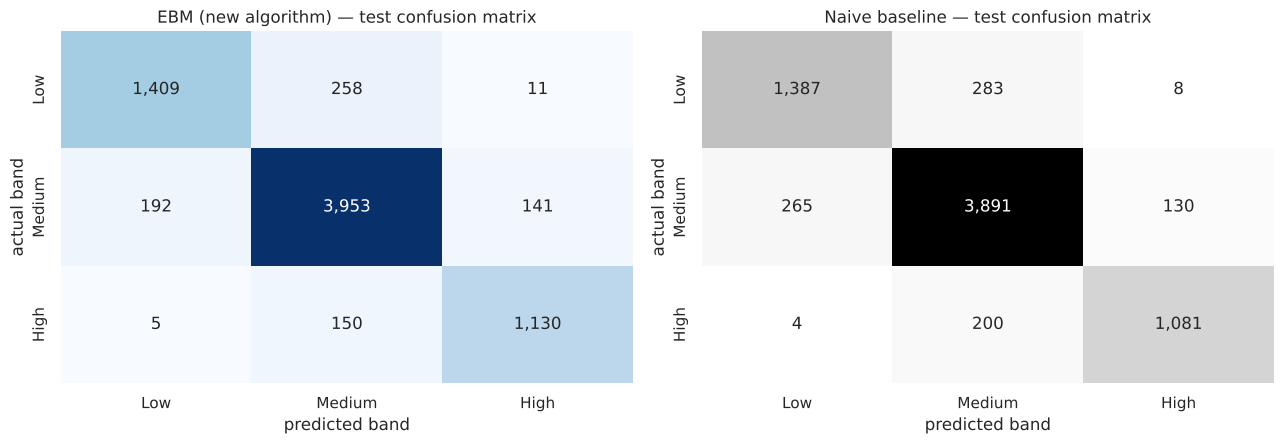

In [17]:
p_test = best.predict_proba(X_test); yhat = p_test.argmax(1)
print(classification_report(y_test, yhat, target_names=BAND_SHORT, digits=3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
cm = confusion_matrix(y_test, yhat)
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=axes[0], xticklabels=BAND_SHORT, yticklabels=BAND_SHORT)
axes[0].set(xlabel="predicted band", ylabel="actual band", title=f"{best_name} — test confusion matrix")
cmn = confusion_matrix(y_test, naive_proba(X_test).argmax(1))
sns.heatmap(cmn, annot=True, fmt=",", cmap="Greys", cbar=False, ax=axes[1], xticklabels=BAND_SHORT, yticklabels=BAND_SHORT)
axes[1].set(xlabel="predicted band", ylabel="actual band", title="Naive baseline — test confusion matrix")
fig.tight_layout(); fig.savefig(FIG / "confusion.png", dpi=120); plt.show()

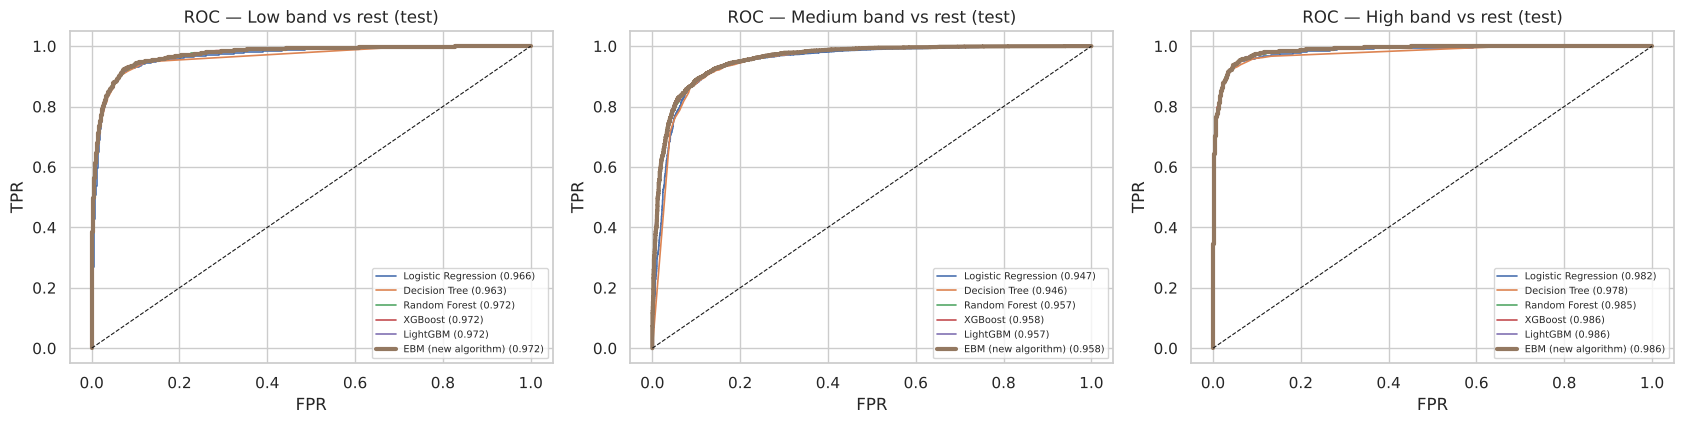

In [18]:
from sklearn.metrics import roc_curve
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
for k, ax in enumerate(axes):
    for n in ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost", "LightGBM", EBM_NAME]:
        p = tuned[n].predict_proba(X_test)[:, k]; fpr, tpr, _ = roc_curve(y_test == k, p)
        ax.plot(fpr, tpr, lw=3 if n == EBM_NAME else 1.2, label=f"{n} ({roc_auc_score(y_test == k, p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=.8); ax.set(title=f"ROC — {BAND_SHORT[k]} band vs rest (test)", xlabel="FPR", ylabel="TPR"); ax.legend(fontsize=7)
fig.tight_layout(); fig.savefig(FIG / "roc_curves.png", dpi=120); plt.show()

### 8.1 Where does the model add value over the naive rule?

In [19]:
# Households whose recent usage is close to a band edge are the hard (and most useful) cases
d = np.minimum(abs(X_test.avg_last_3 - 60), abs(X_test.avg_last_3 - 180))
grp = pd.cut(d, [-1, 10, 25, 50, 1e9], labels=["within 10 units of an edge", "10–25", "25–50", "> 50 units away"])
nv = naive_proba(X_test).argmax(1)
near = pd.DataFrame({"group": grp, "y": y_test.to_numpy(), "ebm": yhat, "naive": nv}).groupby("group", observed=True).apply(
    lambda g: pd.Series({"rows": len(g), "EBM accuracy": (g.ebm == g.y).mean(), "naive accuracy": (g.naive == g.y).mean()}))
near["EBM gain"] = near["EBM accuracy"] - near["naive accuracy"]
near.round(3)

,rows,EBM accuracy,naive accuracy,EBM gain
group,,,,
within 10 units of an edge,1182.0,0.717,0.636,0.081
10–25,1734.0,0.883,0.869,0.014
25–50,2612.0,0.940,0.936,0.004
> 50 units away,1721.0,0.963,0.962,0.001


In [20]:
from sklearn.base import clone
ebm_model = best.named_steps["model"]
print(f"Overfitting check — train {accuracy_score(y_train, best.predict(X_train)):.4f} | validation "
      f"{accuracy_score(y_val, best.predict(X_val)):.4f} | test {accuracy_score(y_test, yhat):.4f}")

# Temporal robustness: train on forecast dates Jan–Jun 2024 only, test on Jul–Sep 2024 (test households)
early, late = train[train.origin <= "2024-06-30"], test[test.origin >= "2024-07-31"]
m_t = clone(ebm_model).fit(early[elec.FEATURES], early.band)
pl = m_t.predict(late[elec.FEATURES])
print(f"Temporal check (train Jan–Jun, test Jul–Sep 2024, new households): accuracy {accuracy_score(late.band, pl):.4f} | "
      f"naive {accuracy_score(late.band, naive_proba(late).argmax(1)):.4f}")

# Value of the household survey: EBM with bill history only
hist_only = elec.HISTORY_FEATURES + elec.CALENDAR
m_h = clone(ebm_model).fit(X_train[hist_only], y_train)
print(f"EBM with bill history only: test accuracy {accuracy_score(y_test, m_h.predict(X_test[hist_only])):.4f} "
      f"(full model {accuracy_score(y_test, yhat):.4f})")

Overfitting check — train 0.9004 | validation 0.9020 | test 0.8956


Temporal check (train Jan–Jun, test Jul–Sep 2024, new households): accuracy 0.8820 | naive 0.8837


EBM with bill history only: test accuracy 0.8943 (full model 0.8956)


In [21]:
# Fairness: does accuracy differ across socio-economic classes (not a model input) or house types?
ev = test.assign(pred=yhat, naive=naive_proba(X_test).argmax(1))
def grp_stats(g):
    return pd.Series({"rows": len(g), "accuracy": (g.pred == g.band).mean(), "naive": (g.naive == g.band).mean(),
                      "macro_f1": f1_score(g.band, g.pred, average="macro"), "share_High": (g.band == 2).mean()})
fair = pd.concat([ev.groupby("socio_economic_class").apply(grp_stats), ev.groupby("house_type").apply(grp_stats),
                  ev.groupby(ev.solar_panels.map({0: "no solar", 1: "solar"})).apply(grp_stats)],
                 keys=["socio-economic class", "house type", "solar"])
fair.round(3)

rows  accuracy  \
socio-economic class SEC A                              1377.0     0.876   
                     SEC B                              1693.0     0.892   
                     SEC C                              2514.0     0.897   
                     SEC D                              1098.0     0.905   
                     SEC E                               567.0     0.928   
house type           Flat / apartment                    198.0     0.874   
                     Other                                99.0     0.859   
                     Single House - Double Floor        2322.0     0.888   
                     Single House - More than 2 floors   216.0     0.935   
                     Single House - Single Floor        4414.0     0.900   
solar                no solar                           6601.0     0.897   
                     solar                               648.0     0.883   

                                                        naive  macro_f1  \
socio-economic class SEC A                              0.859     0.850   
                     SEC B                              0.869     0.879   
                     SEC C                              0.883     0.874   
                     SEC D                              0.885     0.875   
                     SEC E                              0.905     0.926   
house type           Flat / apartment                   0.838     0.896   
                     Other                              0.859     0.852   
                     Single House - Double Floor        0.872     0.875   
                     Single House - More than 2 floors  0.907     0.914   
                     Single House - Single Floor        0.881     0.882   
solar                no solar                           0.879     0.878   
                     solar                              0.858     0.849   

                                                        share_High  
socio-economic class SEC A                                   0.400  
                     SEC B                                   0.193  
                     SEC C                                   0.128  
                     SEC D                                   0.058  
                     SEC E                                   0.037  
house type           Flat / apartment                        0.045  
                     Other                                   0.000  
                     Single House - Double Floor             0.288  
                     Single House - More than 2 floors       0.546  
                     Single House - Single Floor             0.111  
solar                no solar                                0.134  
                     solar                                   0.614

**Interpretation — test results and checks.**

* **Selection rule.** XGBoost had the best raw validation accuracy, but the EBM was statistically tied, so the
  pre-registered rule selects the EBM (equal accuracy + exact explanations). On the untouched test households the
  EBM scores **0.8956 accuracy, 0.880 balanced accuracy, 0.884 macro-F1 and 0.972 macro AUC** — second only to
  CatBoost (0.8967) by 0.1 point.
* **Against the naive rule** ("next month is in the band of my last-3 average") the EBM gains **+1.8 points
  accuracy** and **+0.08 macro AUC**. The gain is concentrated where it matters: for households **within 10 units of
  a band edge** the EBM is right 71.7% of the time vs 63.6% for the naive rule (+8.1 points); far from an edge both
  are ~96% correct. This is the honest headline: most households are easy, and the model earns its keep on the
  borderline ones — exactly those for whom a warning is useful.
* **Per-class.** Medium is easiest (F1 0.914), Low hardest (F1 0.858, recall 0.84): low bills fluctuate in
  relative terms (a 20-unit swing moves a 50-unit home across the 60 edge).
* **Overfitting.** Train 0.900 / validation 0.902 / test 0.896 — no meaningful gap.
* **Temporal check.** Trained on Jan–Jun 2024 forecasts, tested on Jul–Sep 2024 for unseen households: 0.882,
  equal to the naive rule (0.884). The model's advantage shrinks when the season it predicts is not in training,
  which is a genuine limitation (only one year of forecast origins exists).
* **History-only EBM** reaches 0.8943 vs 0.8956 for the full model: once 12 bills are known, the survey adds very
  little. The bills already "contain" the appliances.
* **Fairness.** Accuracy ranges from 0.876 (SEC A, wealthiest) to 0.928 (SEC E), and the EBM beats the naive rule
  in every group. The lower accuracy for SEC A and for flats reflects more variable, higher consumption near the
  180 edge, not a bias against poorer households — but SEC A users should be told the forecast is less certain.
  Solar homes (0.883) are slightly harder because their grid bills depend on sunshine.

## 9. Explainability and interpretation

| Method | Type | Question it answers |
|---|---|---|
| **EBM shape functions** | Glass box, exact, global and local | What did the model learn for each feature? |
| **Partial Dependence (PDP) + ICE** | Model-agnostic, global | How does P(High band) change as one feature changes? |
| **SHAP** | Model-agnostic, global and local | How much does each feature push each prediction? |
| **LIME** | Model-agnostic, local | Which simple rules explain this household's prediction? |

The explanations focus on the **High band**, the expensive outcome a household wants to avoid.

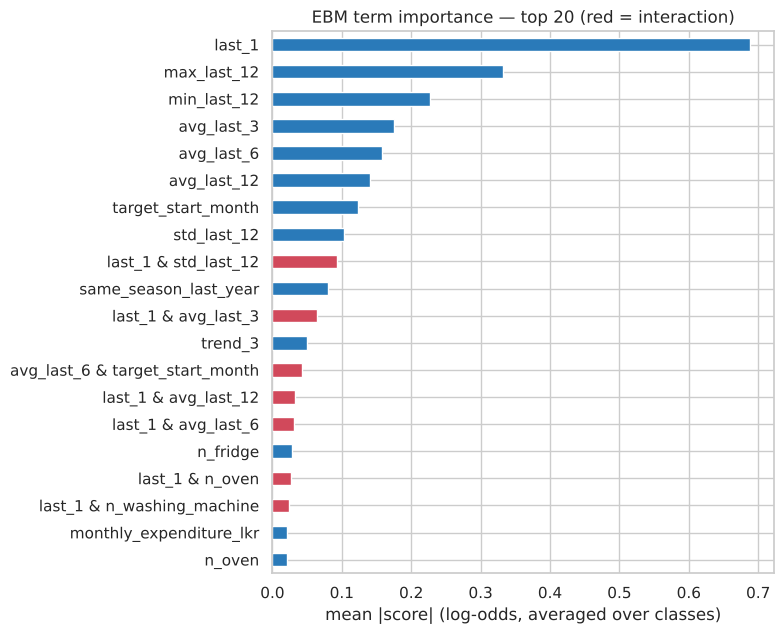

,importance
last_1,0.6883
max_last_12,0.3321
min_last_12,0.2274
avg_last_3,0.1750
avg_last_6,0.1585
avg_last_12,0.1402
target_start_month,0.1230
std_last_12,0.1033
last_1 & std_last_12,0.0934
same_season_last_year,0.0804


In [22]:
imp = pd.Series(ebm_model.term_importances(), index=ebm_model.term_names_).sort_values()
top_imp = imp.tail(20)
fig, ax = plt.subplots(figsize=(8, 6.5))
top_imp.plot.barh(ax=ax, color=["#d1495b" if "&" in t else "#2a7ab9" for t in top_imp.index])
ax.set(xlabel="mean |score| (log-odds, averaged over classes)", title="EBM term importance — top 20 (red = interaction)")
fig.tight_layout(); fig.savefig(FIG / "ebm_importance.png", dpi=120); plt.show()
imp.sort_values(ascending=False).head(20).round(4).to_frame("importance")

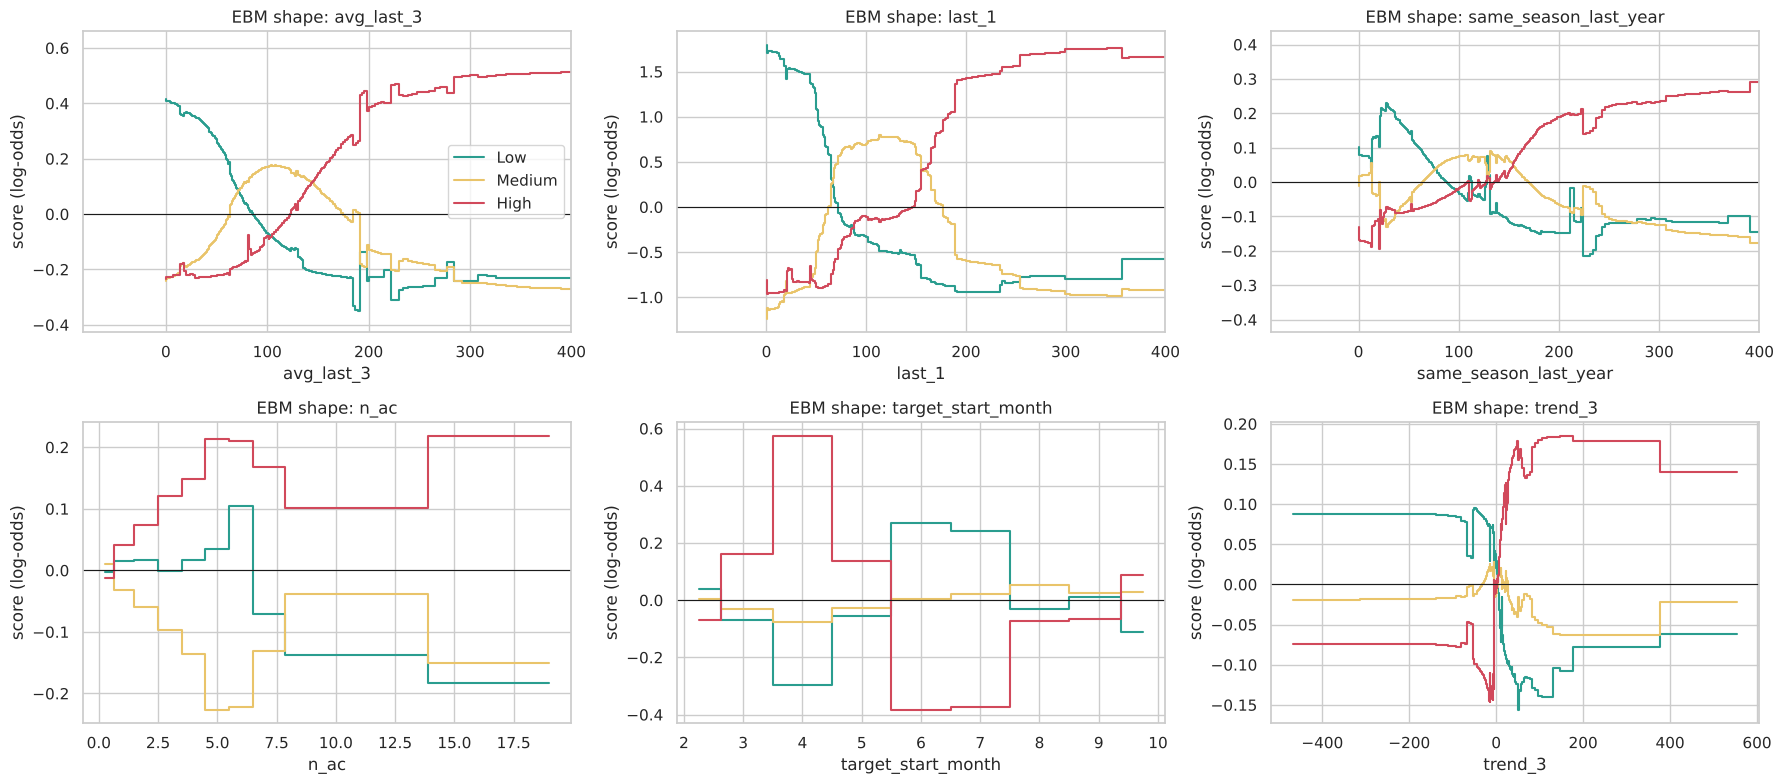

In [23]:
def shape(term):
    i = ebm_model.term_names_.index(term); return ebm_model.explain_global().data(i)

def plot_shape(ax, term, xlabel=None, xmax=None):
    d = shape(term); names = np.asarray(d["names"], dtype=float); sc = np.asarray(d["scores"])
    x = (names[:-1] + names[1:]) / 2 if len(names) == sc.shape[0] + 1 else names
    sc = sc if sc.ndim == 2 else sc[:, None]
    for k in range(sc.shape[1]):
        ax.step(x, sc[:, k], where="mid", color=BAND_COLORS[k] if sc.shape[1] == 3 else "#2a7ab9", label=BAND_SHORT[k] if sc.shape[1] == 3 else None)
    ax.axhline(0, c="k", lw=.8); ax.set(title=f"EBM shape: {term}", xlabel=xlabel or term, ylabel="score (log-odds)")
    if xmax: ax.set_xlim(right=xmax)

fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for ax, (t, xm) in zip(axes.ravel(), [("avg_last_3", 400), ("last_1", 400), ("same_season_last_year", 400),
                                      ("n_ac", None), ("target_start_month", None), ("trend_3", None)]):
    if t in ebm_model.term_names_: plot_shape(ax, t, xmax=xm)
axes[0, 0].legend()
fig.tight_layout(); fig.savefig(FIG / "ebm_shapes.png", dpi=120); plt.show()

In [24]:
appl_terms = [t for t in ["n_ac", "grid_water_heating", "n_water_pump", "n_washing_machine", "n_fridge", "electric_cooking",
                          "solar_panels", "n_geyser", "n_oven", "household_members", "floor_area_sqft", "n_bulbs"] if t in ebm_model.term_names_]
rows_ = []
for t in appl_terms:
    d = shape(t); sc = np.asarray(d["scores"]); sc = sc if sc.ndim == 2 else sc[:, None]
    rows_.append({"feature": t, "High-band score range": sc[:, -1].max() - sc[:, -1].min(),
                  "direction (High band)": "↑ raises" if sc[-1, -1] > sc[0, -1] else "↓ lowers"})
appl = pd.DataFrame(rows_).sort_values("High-band score range", ascending=False)
appl.round(3)

,feature,High-band score range,direction (High band)
4,n_fridge,0.606,↑ raises
2,n_water_pump,0.368,↑ raises
3,n_washing_machine,0.340,↑ raises
7,n_geyser,0.306,↑ raises
9,household_members,0.302,↑ raises
11,n_bulbs,0.235,↑ raises
0,n_ac,0.231,↑ raises
6,solar_panels,0.140,↑ raises
1,grid_water_heating,0.106,↑ raises
8,n_oven,0.103,↑ raises


**Interpretation — what the EBM learned (global).**

* **The last bill dominates** (importance 0.69), followed by the 12-month maximum and minimum and the 3/6/12-month
  averages. This is what an electricity engineer would expect: consumption is highly persistent.
* **Shape functions are sensible and readable.** In `last_1`, the Low score falls steeply between ~40 and ~70 units
  and the High score rises steeply between ~150 and ~190 — the model has rediscovered the 60 and 180 tariff edges
  from data alone. `avg_last_3` shows the same pattern more smoothly.
* **Seasonality matches Sri Lanka's climate.** `target_start_month` pushes towards High for **April** (+0.57, the
  hottest month, inter-monsoon; also Sinhala & Tamil New Year) and away from High for **June–July** (−0.38, the
  south-west monsoon, cooler and wetter, so fewer fans/AC). `trend_3` adds a momentum effect: a rising last quarter
  raises the High score.
* **Interactions** found by GA²M are mostly between history features (e.g. `last_1 × std_last_12`: a high last
  bill is less alarming for a household whose bills always swing).
* **Appliances** have small but correctly signed effects in this model (fridge, water pump, washing machine,
  geyser, household size raise the High score), because the bills already carry this information.

### 9.2 Partial Dependence and ICE

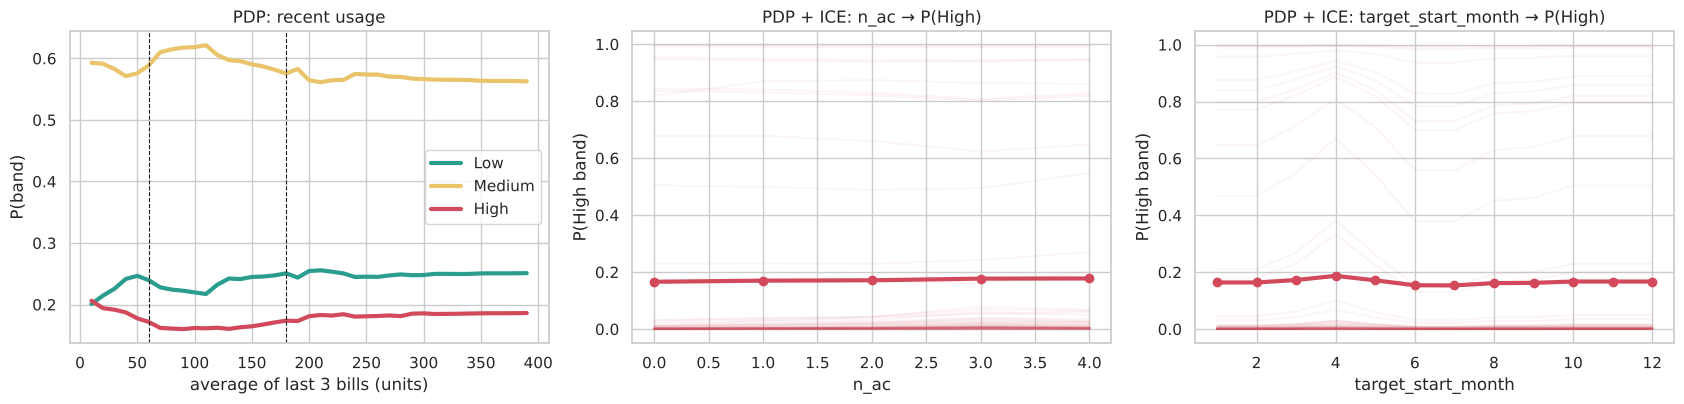

In [25]:
from sklearn.inspection import partial_dependence
pdp_X = X_test.sample(1200, random_state=SEED).astype({c: float for c in elec.NUMERIC})
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
grid = np.arange(10, 400, 10).astype(float)
res = partial_dependence(best, pdp_X, ["avg_last_3"], kind="both", custom_values={"avg_last_3": grid}, response_method="predict_proba")
for k in range(3):
    axes[0].plot(grid, res["average"][k], color=BAND_COLORS[k], lw=3, label=BAND_SHORT[k])
for e in elec.BAND_EDGES: axes[0].axvline(e, c="k", ls="--", lw=.8)
axes[0].set(xlabel="average of last 3 bills (units)", ylabel="P(band)", title="PDP: recent usage"); axes[0].legend()
for ax, feat, vals in [(axes[1], "n_ac", np.arange(0, 5).astype(float)), (axes[2], "target_start_month", np.arange(1, 13).astype(float))]:
    r = partial_dependence(best, pdp_X, [feat], kind="both", custom_values={feat: vals}, response_method="predict_proba")
    for line in r["individual"][2][:60]: ax.plot(vals, line, color="#d1495b", alpha=.06)
    ax.plot(vals, r["average"][2], "o-", color="#d1495b", lw=3); ax.set(xlabel=feat, ylabel="P(High band)", title=f"PDP + ICE: {feat} → P(High)")
fig.tight_layout(); fig.savefig(FIG / "pdp.png", dpi=120); plt.show()

**Interpretation — partial dependence.**

* The PDP for `avg_last_3` is surprisingly **flat**. This is the known weakness of PDP with **correlated features**:
  it changes the 3-month average while holding `last_1`, `max_last_12` etc. fixed, creating unrealistic
  households (e.g. average 300 but last bill 40), and the model — correctly — trusts the other history features.
  This is why we rely on EBM shapes (one feature's own contribution) and the consistent what-if in §9.5 instead.
* The ICE lines for `n_ac` are almost horizontal: once bills are known, adding an AC on paper changes little.
* `target_start_month` shows the April peak and June–July dip for individual households (ICE), with a small
  average effect because most households are far from an edge.

### 9.3 SHAP (for P(High band))

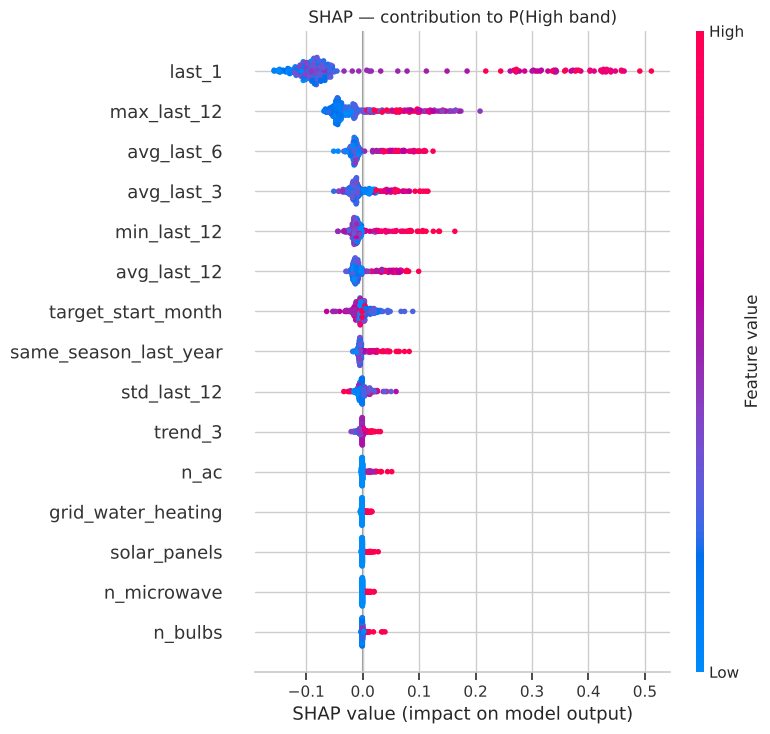

Spearman rank correlation SHAP vs EBM importance: 0.82


,SHAP mean |value|,EBM importance
last_1,0.1349,0.8399
max_last_12,0.0485,0.3400
avg_last_6,0.0233,0.2056
avg_last_3,0.0211,0.2122
min_last_12,0.0194,0.2274
avg_last_12,0.0188,0.1561
target_start_month,0.0111,0.1441
same_season_last_year,0.0091,0.0997
std_last_12,0.0070,0.1579
trend_3,0.0043,0.0500


In [26]:
cats = {c: sorted(X_train[c].dropna().unique()) for c in elec.CATEGORICAL}
def to_num(d):
    d = d.copy()
    for c in elec.CATEGORICAL: d[c] = d[c].map({v: i for i, v in enumerate(cats[c])})
    return d.to_numpy(dtype=float)
def from_num(a):
    d = pd.DataFrame(np.atleast_2d(a), columns=elec.FEATURES)
    for c in elec.CATEGORICAL: d[c] = d[c].round().clip(0, len(cats[c]) - 1).astype(int).map(dict(enumerate(cats[c])))
    return d
predict_fn = lambda a: best.predict_proba(from_num(a))
p_high = lambda a: predict_fn(a)[:, 2]

bg = X_train.sample(100, random_state=SEED); X_sh = X_test.sample(300 if not QUICK else 60, random_state=SEED)
explainer = shap.PermutationExplainer(p_high, shap.maskers.Independent(to_num(bg), max_samples=100), feature_names=elec.FEATURES, seed=SEED)
sv = explainer(to_num(X_sh), silent=True).values
shap_imp = pd.Series(np.abs(sv).mean(0), index=elec.FEATURES).sort_values(ascending=False)
shap.summary_plot(sv, pd.DataFrame(to_num(X_sh), columns=elec.FEATURES), max_display=15, show=False)
plt.title("SHAP — contribution to P(High band)"); plt.tight_layout(); plt.savefig(FIG / "shap_beeswarm.png", dpi=120); plt.show()

ebm_feat = pd.Series(0.0, index=elec.FEATURES)
for t, v in zip(ebm_model.term_names_, ebm_model.term_importances()):
    parts = t.split(" & ")
    for p in parts: ebm_feat[p] += v / len(parts)
from scipy.stats import spearmanr
cmp = pd.DataFrame({"SHAP mean |value|": shap_imp, "EBM importance": ebm_feat}).sort_values("SHAP mean |value|", ascending=False)
print("Spearman rank correlation SHAP vs EBM importance: %.2f" % spearmanr(cmp.iloc[:, 0], cmp.iloc[:, 1]).correlation)
cmp.head(12).round(4)

**Interpretation — SHAP (model-agnostic check).**

* SHAP (permutation explainer, 300 test households, explaining P(High)) ranks the features very similarly to the
  EBM's own importances (**Spearman ρ = 0.82**): `last_1` first by a wide margin, then `max_last_12`, the
  averages and `min_last_12`, then the month.
* The beeswarm shows the expected direction: high values of recent usage push P(High) up, low values push it down.
  AC count and grid water heating are the most influential household features but are an order of magnitude
  weaker than the bills.
* Agreement between two independent explanation methods (built-in glass-box vs post-hoc SHAP) gives confidence
  that the explanations reflect the model, not an artefact of one method.

### 9.4 Local explanations (EBM exact vs LIME) for three households

Likely High | top EBM terms: {'same_season_last_year & n_washing_machine': 0.33, 'avg_last_12': 0.411, 'avg_last_6': 0.454, 'avg_last_3': 0.496, 'target_start_month': 0.575, 'min_last_12': 0.698, 'max_last_12': 0.87, 'last_1': 1.664}


Near the 180 edge | top EBM terms: {'max_last_12': -0.174, 'avg_last_12': -0.121, 'std_last_12': -0.081, 'avg_last_6': -0.031, 'n_rice_cooker': -0.031, 'household_members': -0.031, 'last_1 & same_season_last_year': 0.029, 'last_1': 0.35}
Near the 60 edge | top EBM terms: {'min_last_12': -0.03, 'avg_last_3': -0.021, 'same_season_last_year': 0.021, 'last_1 & std_last_12': 0.022, 'avg_last_12': 0.035, 'std_last_12': 0.044, 'max_last_12': 0.143, 'last_1': 0.264}


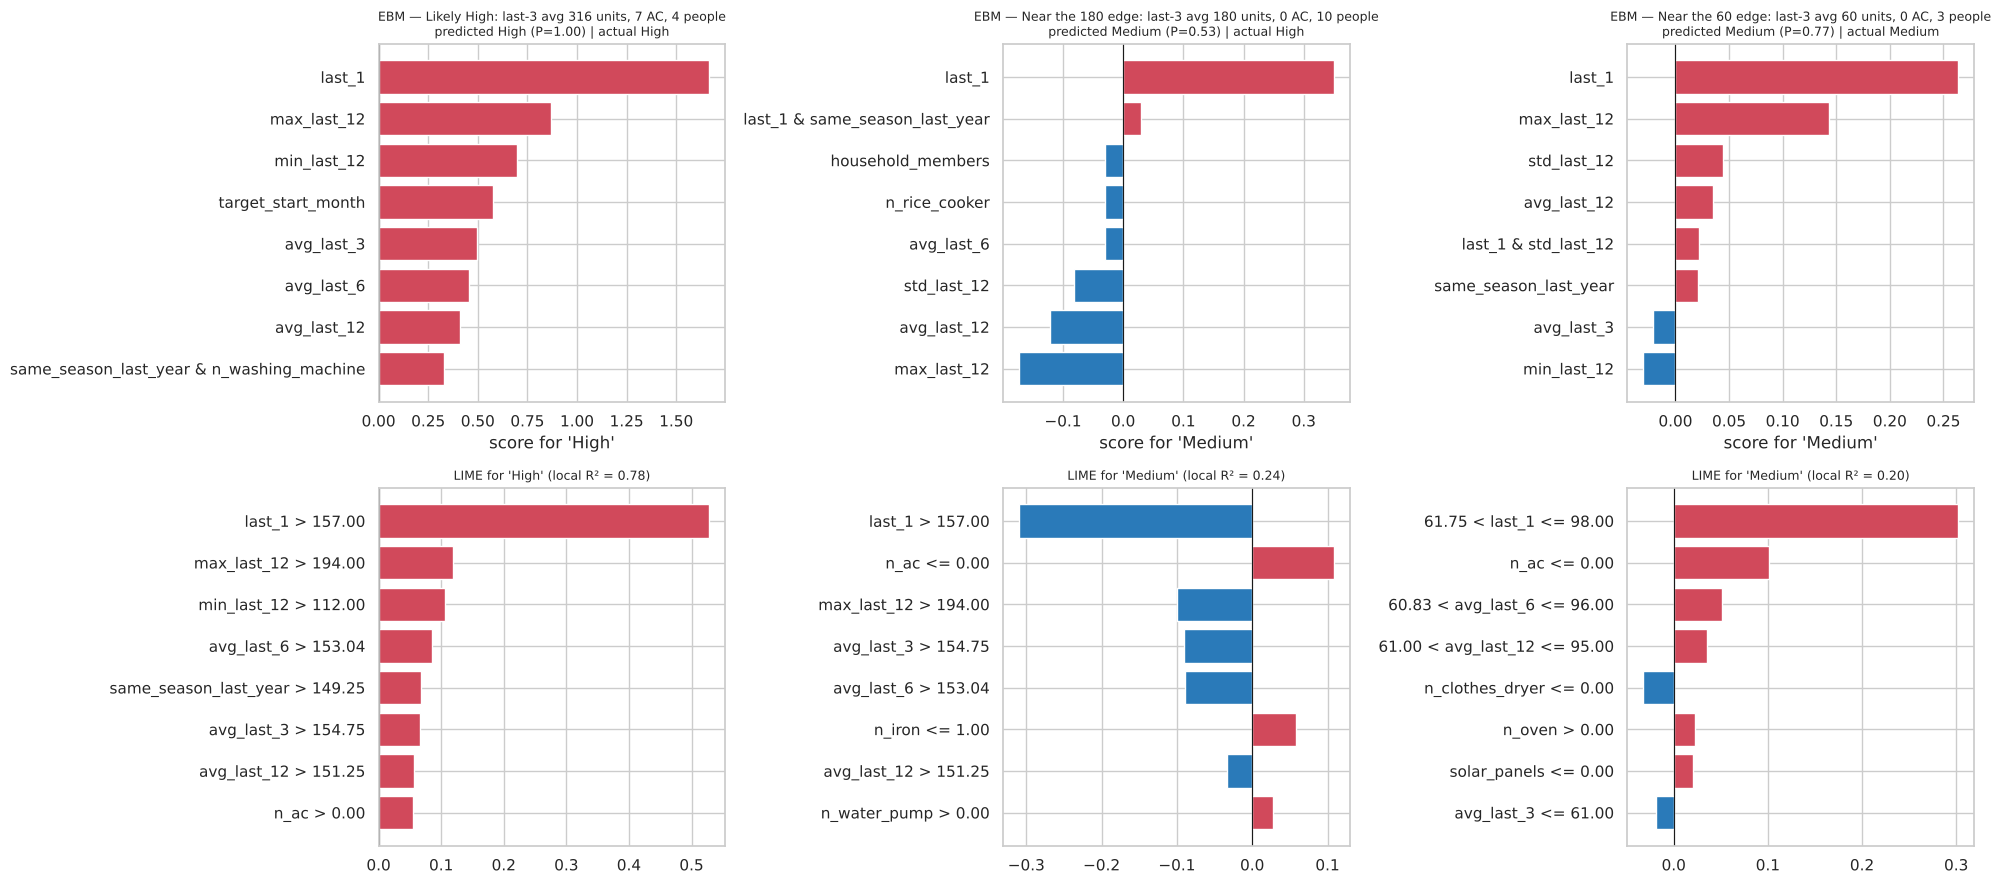

In [27]:
from lime.lime_tabular import LimeTabularExplainer
cat_idx = [elec.FEATURES.index(c) for c in elec.CATEGORICAL]
lime_bg = X_train.sample(2000, random_state=SEED)
lime_exp = LimeTabularExplainer(np.nan_to_num(to_num(lime_bg), nan=0.0), feature_names=elec.FEATURES, class_names=BAND_SHORT,
                                categorical_features=cat_idx, categorical_names={i: cats[elec.FEATURES[i]] for i in cat_idx},
                                discretize_continuous=True, random_state=SEED)
tp = X_test.assign(pH=p_test[:, 2], y=y_test.to_numpy(), pred=yhat)
cases = {"Likely High": tp.pH.idxmax(),
         "Near the 180 edge": (tp.avg_last_3 - 180).abs().idxmin(),
         "Near the 60 edge": (tp.avg_last_3 - 60).abs().idxmin()}
fig, axes = plt.subplots(2, 3, figsize=(20, 9))
for k, (label, idx) in enumerate(cases.items()):
    row = X_test.loc[[idx]]; r = tp.loc[idx]; cls = int(r.pred)
    title = (f"{label}: last-3 avg {r.avg_last_3:.0f} units, {int(r.n_ac)} AC, {int(r.household_members)} people\n"
             f"predicted {BAND_SHORT[cls]} (P={p_test[X_test.index.get_loc(idx), cls]:.2f}) | actual {BAND_SHORT[int(r.y)]}")
    contrib = pd.DataFrame(ebm_model.eval_terms(row)[0], index=ebm_model.term_names_)
    c = contrib.iloc[:, cls] if contrib.shape[1] == 3 else contrib.iloc[:, 0]
    c = c.loc[c.abs().sort_values().index[-8:]].sort_values()
    axes[0, k].barh(c.index, c.values, color=["#d1495b" if v > 0 else "#2a7ab9" for v in c.values])
    axes[0, k].axvline(0, c="k", lw=.8); axes[0, k].set_title("EBM — " + title, fontsize=9); axes[0, k].set_xlabel(f"score for '{BAND_SHORT[cls]}'")
    e = lime_exp.explain_instance(np.nan_to_num(to_num(row)[0], nan=0.0), predict_fn, labels=(cls,), num_features=8, num_samples=4000)
    w = pd.DataFrame(e.as_list(label=cls), columns=["rule", "weight"]).iloc[::-1]
    axes[1, k].barh(w.rule, w.weight, color=["#d1495b" if v > 0 else "#2a7ab9" for v in w.weight])
    axes[1, k].axvline(0, c="k", lw=.8); axes[1, k].set_title(f"LIME for '{BAND_SHORT[cls]}' (local R² = {e.score:.2f})", fontsize=9)
    print(label, "| top EBM terms:", c.round(3).to_dict())
fig.tight_layout(); fig.savefig(FIG / "local_explanations.png", dpi=120); plt.show()

**Interpretation — local explanations (EBM vs LIME).**

* **Clear High case** (last-3 average 316 units, 7 ACs): both methods agree — the high last bill, high 12-month
  max/min and the averages drive P(High) = 1.00. LIME's local surrogate fits well (R² 0.78).
* **Near the 180 edge** (average 180 units, 10 people): the EBM predicts Medium with only P = 0.53; the actual was
  High. The EBM shows the tension — the last bill pushes towards Medium, while a high 12-month max pushes away.
  This is an honest borderline case and the app reports it as uncertain.
* **Near the 60 edge**: correctly Medium (P = 0.77).
* LIME's surrogate is weak on the borderline cases (R² 0.20–0.24) and its explanations change with sampling;
  the **EBM's explanation is exact** (the contributions sum to the model's score), which is the main reason the
  EBM was chosen for the user-facing app.

### 9.5 From explanation to advice: usage scenarios
Section 8.1 showed that, once 12 months of bills are known, appliance details add almost no predictive
power: a home's appliances are already reflected in its bills. Advice is therefore based on **usage**. For a
household near the 180-unit edge, the scenarios below show how the predicted band changes if it reduces
consumption.

In [28]:
cand = tp[(tp.avg_last_3.between(170, 200))].sort_values("pH")
base_row = X_test.loc[[cand.index[len(cand) // 2]]]
print(f"Household: last bill {base_row.last_1.iloc[0]:.0f}, last-3 average {base_row.avg_last_3.iloc[0]:.0f}, "
      f"12-month average {base_row.avg_last_12.iloc[0]:.0f}, 12-month max {base_row.max_last_12.iloc[0]:.0f} units")
out = []
for cut in [0, 0.05, 0.10, 0.20]:
    pr = best.predict_proba(elec.scale_usage(base_row, -cut))[0]
    out.append({"usage change": f"-{int(cut*100)}%", "P(Low)": pr[0], "P(Medium)": pr[1], "P(High)": pr[2], "predicted": BAND_SHORT[pr.argmax()]})
pd.DataFrame(out).round(3)

Household: last bill 114, last-3 average 179, 12-month average 198, 12-month max 223 units


,usage change,P(Low),P(Medium),P(High),predicted
0,-0%,0.011,0.346,0.643,High
1,-5%,0.012,0.360,0.629,High
2,-10%,0.014,0.418,0.568,High
3,-20%,0.032,0.566,0.402,Medium


### 9.6 New households with no bill history: what do appliances tell us?
New connections, recently moved families and planners have no 12-month history. A second EBM is trained on
the **home and appliance details only** (same households, same split, same tuned hyperparameters). It is
less accurate, but this is where the appliance effects can be estimated properly, which gives the
"which appliances drive consumption" insight.

New-household model (no bills) — test accuracy 0.6062 | balanced 0.5203 | macro AUC 0.7111 | always-'Medium' baseline 0.5913


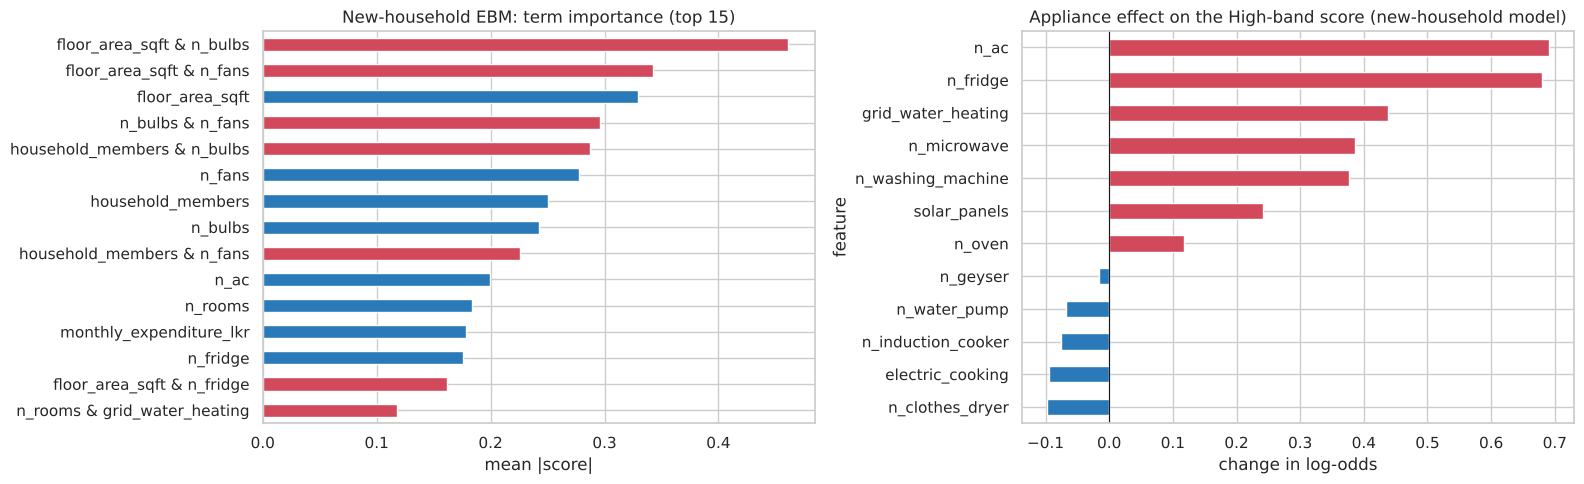

,effect on High score (0 → 1 unit)
feature,
n_clothes_dryer,-0.098
electric_cooking,-0.094
n_induction_cooker,-0.075
n_water_pump,-0.068
n_geyser,-0.016
n_oven,0.118
solar_panels,0.242
n_washing_machine,0.377
n_microwave,0.386


In [29]:
prof_params = {k: v for k, v in ebm_model.get_params().items()}
ebm_profile = ExplainableBoostingClassifier(**prof_params).fit(train[elec.PROFILE_FEATURES], y_train)
pp = ebm_profile.predict_proba(test[elec.PROFILE_FEATURES])
majority = np.bincount(y_train).argmax()
print(f"New-household model (no bills) — test accuracy {accuracy_score(y_test, pp.argmax(1)):.4f} | "
      f"balanced {balanced_accuracy_score(y_test, pp.argmax(1)):.4f} | macro AUC {roc_auc_score(y_test, pp, multi_class='ovr'):.4f} | "
      f"always-'Medium' baseline {accuracy_score(y_test, np.full(len(y_test), majority)):.4f}")
imp_p = pd.Series(ebm_profile.term_importances(), index=ebm_profile.term_names_).sort_values().tail(15)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
imp_p.plot.barh(ax=axes[0], color=["#d1495b" if "&" in t else "#2a7ab9" for t in imp_p.index])
axes[0].set(title="New-household EBM: term importance (top 15)", xlabel="mean |score|")
eff = []
for t in ["n_ac", "n_washing_machine", "n_fridge", "n_water_pump", "n_geyser", "grid_water_heating", "solar_panels",
          "electric_cooking", "n_oven", "n_microwave", "n_induction_cooker", "n_clothes_dryer"]:
    if t in ebm_profile.term_names_:
        d = ebm_profile.explain_global().data(ebm_profile.term_names_.index(t)); sc = np.asarray(d["scores"])
        sc = sc if sc.ndim == 2 else sc[:, None]
        eff.append({"feature": t, "effect on High score (0 → 1 unit)": sc[min(1, len(sc) - 1), -1] - sc[0, -1]})
eff = pd.DataFrame(eff).set_index("feature").iloc[:, 0].sort_values()
eff.plot.barh(ax=axes[1], color=["#2a7ab9" if v < 0 else "#d1495b" for v in eff])
axes[1].axvline(0, c="k", lw=.8); axes[1].set(title="Appliance effect on the High-band score (new-household model)", xlabel="change in log-odds")
fig.tight_layout(); fig.savefig(FIG / "new_household_model.png", dpi=120); plt.show()
eff.round(3).to_frame()

## 10. Saving the model and running inference

The full pipeline is saved with `joblib` (pickle), together with metadata. The Streamlit app and the
FastAPI service load exactly this file.

In [30]:
import joblib
joblib.dump(best, MODELS / "tariff_band_model.pkl")
joblib.dump(ebm_profile, MODELS / "new_household_model.pkl")
row = test_table.set_index("model").loc[best_name]; nrow = test_table.set_index("model").loc["Naive: band of last-3-bill average"]
meta = {"model_name": best_name, "algorithm": "Explainable Boosting Machine (InterpretML GA2M), multiclass", "version": "1.0.0",
        "features": elec.FEATURES, "bands": elec.BANDS, "band_edges": list(elec.BAND_EDGES), "horizon_months": elec.HORIZON,
        "best_params": cv_table.set_index("model").loc[best_name, "best_params"],
        "test_metrics": {k: round(float(row[k]), 4) for k in ["accuracy", "balanced_acc", "macro_f1", "weighted_f1", "macro_auc", "log_loss"]},
        "naive_test_accuracy": round(float(nrow["accuracy"]), 4),
        "new_household_model": {"features": elec.PROFILE_FEATURES, "test_accuracy": round(float(accuracy_score(y_test, pp.argmax(1))), 4),
                                "test_macro_auc": round(float(roc_auc_score(y_test, pp, multi_class="ovr")), 4)},
        "n_households": {"train": int(train.household_ID.nunique()), "validation": int(val.household_ID.nunique()), "test": int(test.household_ID.nunique())},
        "n_rows": {"train": len(train), "validation": len(val), "test": len(test)},
        "data_citation": "LIRNEasia & LECO (2026). Residential Electricity Consumption Dataset for Sri Lanka (RECON-SL). IEEE DataPort. doi:10.21227/n1dk-q860"}
(MODELS / "model_meta.json").write_text(json.dumps(meta, indent=2, default=str))
test_table.round(4).to_csv(MODELS / "model_comparison.csv", index=False)
cv_table.round(4).to_csv(MODELS / "tuning_results.csv", index=False)  # used by mlops/track_experiments.py
val_table.round(4).to_csv(MODELS / "validation_results.csv", index=False)
import monitoring; monitoring.save_reference(X_train, y_train, MODELS / "drift_reference.json")  # training baseline for drift checks
lime_bg.to_csv(MODELS / "lime_background.csv", index=False)
print(json.dumps(meta, indent=2, default=str))

{
  "model_name": "EBM (new algorithm)",
  "algorithm": "Explainable Boosting Machine (InterpretML GA2M), multiclass",
  "version": "1.0.0",
  "features": [
    "last_1",
    "avg_last_3",
    "avg_last_6",
    "avg_last_12",
    "std_last_12",
    "max_last_12",
    "min_last_12",
    "trend_3",
    "same_season_last_year",
    "zero_months_12",
    "household_members",
    "floor_area_sqft",
    "monthly_expenditure_lkr",
    "n_rooms",
    "n_bulbs",
    "n_fans",
    "n_ac",
    "solar_panels",
    "electric_cooking",
    "grid_water_heating",
    "home_business",
    "n_fridge",
    "n_washing_machine",
    "n_iron",
    "n_rice_cooker",
    "n_tv",
    "n_kettle",
    "n_oven",
    "n_microwave",
    "n_water_pump",
    "n_geyser",
    "n_laptop",
    "n_computer",
    "n_induction_cooker",
    "n_water_heater",
    "n_clothes_dryer",
    "n_vacuum",
    "house_type",
    "target_start_month"
  ],
  "bands": [
    "Low (\u226460 units)",
    "Medium (61\u2013180 units)",
    "Hig

In [31]:
loaded = joblib.load(MODELS / "tariff_band_model.pkl")
demo = S[S.household_ID.isin(demo_hh)].sort_values(["household_ID", "origin"]).groupby("household_ID").tail(1)
out = demo[["household_ID", "origin", "avg_last_3", "n_ac", "household_members"]].copy()
pr = loaded.predict_proba(demo[elec.FEATURES])
out["predicted band"] = [BAND_SHORT[i] for i in pr.argmax(1)]; out["P(High)"] = pr[:, 2].round(3)
out["actual next-month units"] = demo.target_kwh.values; out["actual band"] = [BAND_SHORT[i] for i in demo.band]
out

,household_ID,origin,avg_last_3,n_ac,household_members,predicted band,P(High),actual next-month units,actual band
32564,ID0364,2024-09-30,95.666667,0.0,4,Medium,0.000,97.0,Medium
34839,ID2662,2024-09-30,92.333333,0.0,3,Medium,0.001,93.0,Medium
35320,ID3149,2024-09-30,162.666667,0.0,4,Medium,0.250,184.0,High


In [32]:
# A brand-new household typed in by a user (12 bills, oldest first, plus home details)
bills_12 = [150, 160, 175, 190, 185, 170, 160, 158, 165, 172, 178, 182]
home = {"household_members": 5, "floor_area_sqft": 1800, "n_ac": 1, "n_fridge": 1, "n_washing_machine": 1, "grid_water_heating": 1}
r = elec.make_input_row(bills_12, target_month=4, household=home)
pr = loaded.predict_proba(r)[0]
print({b: round(float(p), 3) for b, p in zip(BAND_SHORT, pr)}, "->", BAND_SHORT[pr.argmax()])

{'Low': 0.001, 'Medium': 0.216, 'High': 0.782} -> High


## 11. Critical discussion

### Limitations
* **Accuracy ceiling.** ~89.6% test accuracy is close to the ceiling for one-month-ahead band forecasting from
  bills: a naive rule already gets 87.7%. The model's real value is on borderline households (+8 points within
  10 units of an edge) and in calibrated probabilities (AUC 0.97 vs 0.89).
* **One year of forecasts.** Forecast origins span only Jan–Sep 2024; the temporal check (train Jan–Jun, test
  Jul–Sep) shows no gain over the naive rule for unseen months. More years are needed to learn seasonality robustly.
* **Survey timing.** Household and appliance details come from survey wave 1 (Dec 2023 – Feb 2024) and are treated
  as constant; homes that bought an AC later are misdescribed.
* **Usage what-if is not causal.** §9.5 scales a household's whole history; it shows how the *model* responds to a
  household that uses X% less, not a measured effect of an intervention.
* **New-household model** is weak (60.6% vs 59.1% always-Medium; AUC 0.71). It is useful for *which appliances
  matter*, not as a reliable forecast.

### Data quality
* 57 consumption values were text with thousands separators ("1,159") and were converted; 590 readings were blank; values above 3,000
  units/month were treated as errors; single missing months were interpolated (limit 1), and samples need ≥10 of
  12 history bills. Meter-reading dates vary, so a "month" is a billing month, not a calendar month.

### Bias and fairness
* RECON-SL is a sample of Sri Lankan households, not a census: rural and estate-sector households may be
  under-represented, and results by socio-economic class show the model is **less accurate for wealthier (SEC A)
  households** (0.876) than for SEC E (0.928). Socio-economic class is deliberately **not** a model input — it is
  used only to audit fairness — so the model cannot treat households differently because of their class.

### Ethics and privacy
* Monthly consumption reveals occupancy and lifestyle. The app runs locally and stores nothing; the batch mode for
  utilities should only be used on data customers have consented to. The dataset's licence is not stated in its
  README, so the raw data are not redistributed in the public repository (`.gitignore`), only instructions to obtain it.
* The tool should **inform, not penalise**: it must never be used to deny connections, change tariffs or target
  customers.

### Impact
* Sri Lanka's domestic tariff is block-based, so crossing 60 or 180 units sharply raises the unit price. An early,
  explained warning ("you are likely to cross 180 units next month; you need ~X fewer units") lets households act
  before the bill arrives, and lets the CEB/LECO plan demand-side campaigns for borderline customers.

### Future work
* Add more years and weather data (temperature, rainfall); forecast the exact kWh with prediction intervals;
  update the tariff edges automatically when the PUCSL revises them; use smart-meter data for daily warnings.

### References
1. LIRNEasia & LECO (2026). *Residential Electricity Consumption Dataset for Sri Lanka (RECON-SL).* IEEE DataPort. doi:10.21227/n1dk-q860
2. Lou, Y., Caruana, R., Gehrke, J., Hooker, G. (2013). *Accurate intelligible models with pairwise interactions.* KDD.
3. Nori, H., Jenkins, S., Koch, P., Caruana, R. (2019). *InterpretML: A unified framework for machine learning interpretability.* arXiv:1909.09223.
4. Lundberg, S. M., Lee, S.-I. (2017). *A unified approach to interpreting model predictions.* NeurIPS.
5. Ribeiro, M. T., Singh, S., Guestrin, C. (2016). *"Why should I trust you?" Explaining the predictions of any classifier.* KDD.
6. Public Utilities Commission of Sri Lanka — domestic electricity tariff schedule.